# Modèles Génératifs avec PyTorch — Première Partie
**TP : IA Générative Multi-Modale**

Plan :
0. Projet Python avec UV + dépendances
1. Chargement du dataset MNIST
2. Modèle discriminatif (classifieur)
3. Auto-encodeur simple
4. Variational Autoencoder (VAE)

## 0. Préparation de l'environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.15.0+cpu
Device : cpu


## 1. Chargement du dataset MNIST

MNIST : 70 000 images de chiffres manuscrits (60 000 train / 10 000 test), en niveaux de gris, 28×28 pixels, 10 classes (0–9).

In [2]:
# Transformation : PIL -> tenseur float dans [0, 1], forme (1, 28, 28).
# On garde [0, 1] (pas de normalisation centrée) : c'est pratique pour
# les auto-encodeurs / VAE qui reconstruisent avec une sigmoïde + BCE.
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Taille train :", len(train_dataset))
print("Taille test  :", len(test_dataset))
print("Classes      :", train_dataset.classes)

Taille train : 60000
Taille test  : 10000
Classes      : ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


Batch images : torch.Size([128, 1, 28, 28])
Batch labels : torch.Size([128])
Min / Max pixel : 0.0 1.0


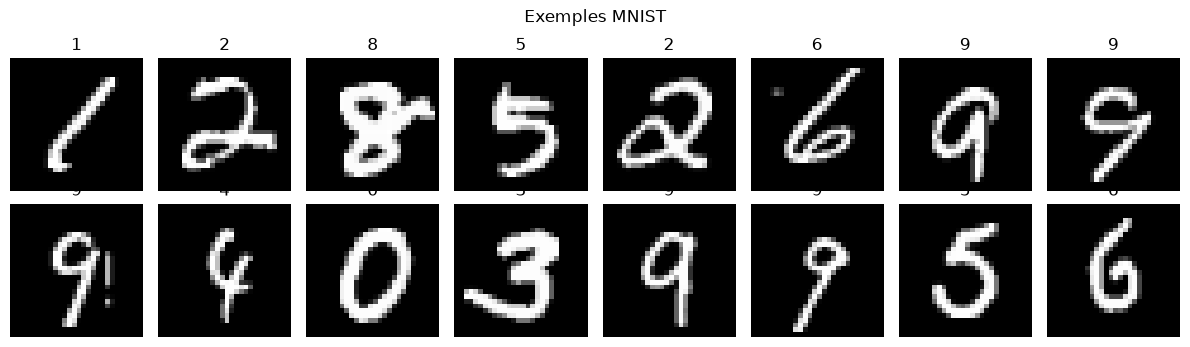

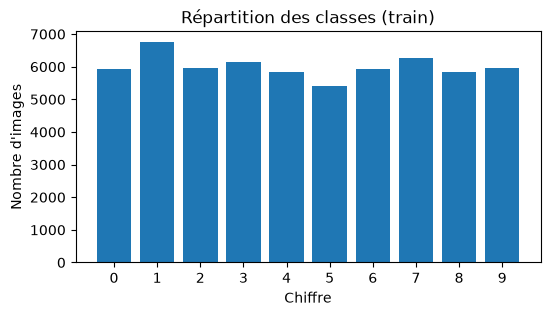

In [3]:
# Visualisation d'un batch
images, labels = next(iter(train_loader))
print("Batch images :", images.shape)   # (B, 1, 28, 28)
print("Batch labels :", labels.shape)
print("Min / Max pixel :", images.min().item(), images.max().item())

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(int(lbl))
    ax.axis("off")
plt.suptitle("Exemples MNIST")
plt.tight_layout()
plt.show()

# Distribution des classes
counts = torch.bincount(train_dataset.targets, minlength=10)
plt.figure(figsize=(6, 3))
plt.bar(range(10), counts.numpy())
plt.xticks(range(10))
plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.title("Répartition des classes (train)")
plt.show()

## 2. Modèle discriminatif (classifieur)

Un modèle **discriminatif** apprend la distribution conditionnelle $p(y \mid x)$ : étant donnée une image $x$, il prédit la classe $y$. Il ne sait pas *générer* de nouvelles images — c'est le point de comparaison avec les modèles génératifs qui suivent, qui apprennent (une approximation de) $p(x)$.

On entraîne un petit CNN avec la cross-entropy.

In [4]:
class Classifier(nn.Module):
    """Petit CNN : 2 blocs conv + 2 couches denses -> 10 logits."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # (32, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (32, 14, 14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (64, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (64, 7, 7)
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10),  # logits (la softmax est dans cross_entropy)
        )

    def forward(self, x):
        return self.head(self.features(x))


classifier = Classifier().to(device)
print(classifier)
print("Nombre de paramètres :", sum(p.numel() for p in classifier.parameters()))

Classifier(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Nombre de paramètres : 421642


In [5]:
EPOCHS_CLF = 3
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
history_clf = {"loss": [], "acc": []}

for epoch in range(1, EPOCHS_CLF + 1):
    classifier.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = classifier(x)
        loss = F.cross_entropy(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += x.size(0)

    history_clf["loss"].append(total_loss / n)
    history_clf["acc"].append(correct / n)
    print(f"Époque {epoch}/{EPOCHS_CLF} - loss : {total_loss / n:.4f} - acc : {correct / n:.4f}")

Époque 1/3 - loss : 0.2794 - acc : 0.9127


Époque 2/3 - loss : 0.0733 - acc : 0.9777


Époque 3/3 - loss : 0.0529 - acc : 0.9840


C:\Users\yassi\tp-modeles-generatifs\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy test : 0.9881


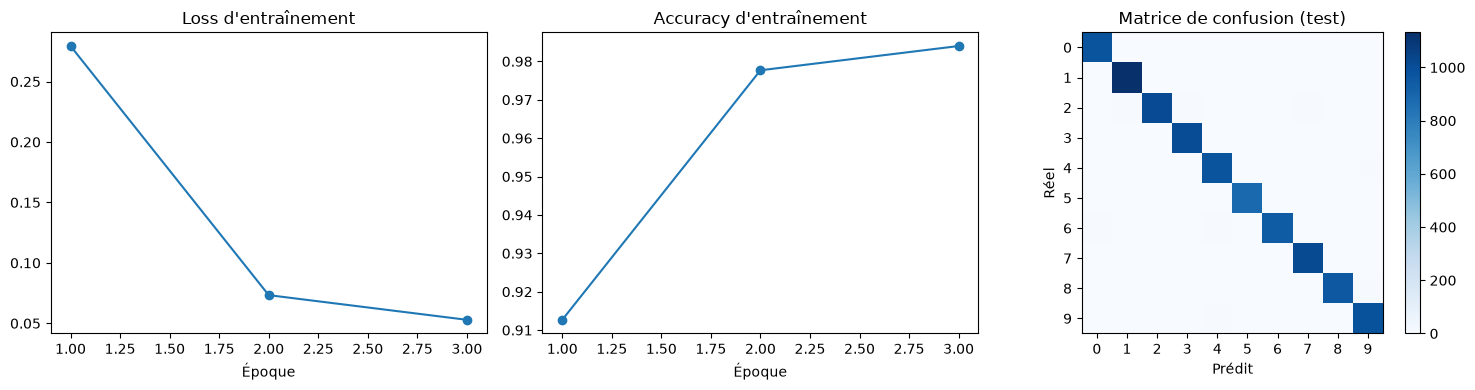

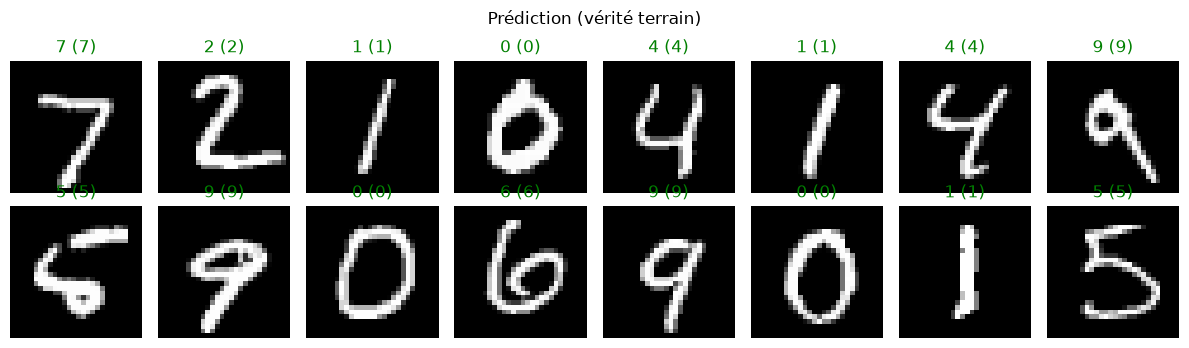

In [6]:
from torcheval.metrics import MulticlassAccuracy, MulticlassConfusionMatrix


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    acc = MulticlassAccuracy(num_classes=10)
    cm = MulticlassConfusionMatrix(num_classes=10)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        preds = model(x).argmax(dim=1).cpu()
        acc.update(preds, y.cpu())
        cm.update(preds, y.cpu())
    return acc.compute().item(), cm.compute()


test_acc, conf_mat = evaluate_classifier(classifier, test_loader)
print(f"Accuracy test : {test_acc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(range(1, EPOCHS_CLF + 1), history_clf["loss"], marker="o")
axes[0].set_title("Loss d'entraînement")
axes[0].set_xlabel("Époque")
axes[1].plot(range(1, EPOCHS_CLF + 1), history_clf["acc"], marker="o")
axes[1].set_title("Accuracy d'entraînement")
axes[1].set_xlabel("Époque")
im = axes[2].imshow(conf_mat.numpy(), cmap="Blues")
axes[2].set_title("Matrice de confusion (test)")
axes[2].set_xlabel("Prédit")
axes[2].set_ylabel("Réel")
axes[2].set_xticks(range(10))
axes[2].set_yticks(range(10))
fig.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

# Quelques prédictions sur le test set
x, y = next(iter(test_loader))
with torch.no_grad():
    preds = classifier(x.to(device)).argmax(dim=1).cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, p, t in zip(axes.flat, x, preds, y):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{p.item()} ({t.item()})", color="green" if p == t else "red")
    ax.axis("off")
plt.suptitle("Prédiction (vérité terrain)")
plt.tight_layout()
plt.show()